In [8]:
import mne
import copy
import torch
import wandb
import pickle
import pathlib

from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from scripts.dataset_manager import read_raw_dataset

# Feature extraction

In [9]:
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')
EPOCH_FILTERED_DATASET_NAME = pathlib.Path('data/epoch_dataset_filtered')

def merge_epochs_dict(epochs_dict):
    """Merges the dict of epochs into a single epoch object, preserving subject and session identification in the metadata."""
    all_epochs = []

    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()

            # build/extend metadata with subject + session
            n = len(ep)
            extra = pd.DataFrame(
                {"subject": [subj] * n, "session": [sess] * n},
                index=ep.metadata.index if ep.metadata is not None else range(n),
            )

            if ep.metadata is None:
                ep.metadata = extra
            else:
                # avoid clobbering if these columns already exist
                meta = ep.metadata.copy()
                meta["subject"] = subj
                meta["session"] = sess
                ep.metadata = meta

            all_epochs.append(ep)

    merged = mne.concatenate_epochs(all_epochs)
    return merged

def query_epochs(epochs, query):
    ep = epochs.copy()
    keep_idx = ep.metadata.query(query).index
    mask = ep.metadata.index.isin(keep_idx)
    return ep[mask]

epoch_dict = read_raw_dataset(EPOCH_DATASET_NAME)
epochs = merge_epochs_dict(epoch_dict)
epochs_scaled = epochs.copy()
epochs_scaled.load_data().apply_function(
    lambda x: (x - x.mean()) / (x.std() + 1e-12), channel_wise=True
)
filtered_epochs = query_epochs(epochs, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()

Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset\subject_21\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
1208 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset\subject_21\session_2\session-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
653 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset\subject_22\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
1609 matching events found
No baseline correction 

C:\Users\nicol\AppData\Local\Temp\ipykernel_7156\3189192329.py:30: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


Adding metadata with 54 columns
35031 matching events found
Applying baseline correction (mode: mean)


# Model training & inference

## Random Forest

Input:

--------------------------------------------------------------------------
FILTERING AND BASELINE ARE PARADIGM-SPECIFIC
--------------------------------------------------------------------------

```
  paradigm   high-pass      low-pass   epoch          baseline
  --------   -----------    --------   ------------   -------------------------
  MI         0.5-4 Hz       40 Hz      0.5 .. 3.5 s   none (log-power handles it)
  P300       0.1-0.5 Hz     20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
  SPN        <= 0.05 Hz !   20-30 Hz   -2.0 .. 0.5 s  cue-locked, NOT -0.2..0 s !
  ErrP       0.1-1 Hz       20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
```

### Experiment tracking (Weights & Biases)

Every model-training run below logs its config, training curves and test metrics to W&B. `wandb_start_run` / `wandb_log_test_results` / `wandb_finish_run` are model-agnostic — `train_eegnet` already uses them, and future models (Random Forest, Conformer, ...) should reuse the same three helpers instead of duplicating logging code.

In [10]:
WANDB_PROJECT = "eeg-pinch-classification"

wandb.login()


def wandb_start_run(model_name: str, run_name: Optional[str] = None, config: Optional[dict] = None, group: Optional[str] = None, tags: Optional[list[str]] = None, enabled: bool = True):
    """Start a W&B run for one model-training run, shared across model types.

    `model_name` (e.g. "EEGNet", "RandomForest", "Conformer") is stored in the config
    and used as the default group, so runs from different models stay comparable in
    the same project. Set enabled=False to skip tracking (e.g. quick local debugging).
    """
    if not enabled:
        return None
    return wandb.init(
        project=WANDB_PROJECT,
        group=group or model_name,
        job_type=model_name,
        name=run_name,
        tags=[model_name, *(tags or [])],
        config={"model": model_name, **(config or {})},
        reinit="finish_previous",  # auto-finish a dangling run, e.g. after a KeyboardInterrupt
    )


def wandb_log_test_results(run, *, test_accuracy: float, y_true, y_pred, classes, test_loss: Optional[float] = None, extra: Optional[dict] = None):
    """Log final test metrics + confusion matrix. Call once per run, before wandb_finish_run."""
    if run is None:
        return
    summary = {"test/accuracy": test_accuracy, **(extra or {})}
    if test_loss is not None:
        summary["test/loss"] = test_loss
    run.summary.update(summary)
    run.log({
        "test/confusion_matrix": wandb.plot.confusion_matrix(
            preds=[int(p) for p in y_pred],
            y_true=[int(t) for t in y_true],
            class_names=[str(c) for c in classes],
        )
    })


def wandb_finish_run(run):
    if run is not None:
        run.finish()

## EEGNet

This is an implementation of EEGNet according to the original paper (Lawhern et al., 2018) in PyTorch.

Input: The EEGNet takes the raw measurements as inputs.

In [27]:
# region EEGNet

# --------------------------------------------------------------------------- #
# Layers with Keras-style max-norm weight constraints
# --------------------------------------------------------------------------- #
class ConstrainedConv2d(nn.Conv2d):
    """Conv2d whose per-filter L2 weight norm is clipped, like Keras max_norm."""

    def __init__(self, *args, max_norm: float = 1.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.max_norm = max_norm

    def forward(self, x):
        with torch.no_grad():
            self.weight.copy_(torch.renorm(self.weight, p=2, dim=0, maxnorm=self.max_norm))
        return super().forward(x)


class ConstrainedLinear(nn.Linear):
    """Linear layer with max-norm constraint on each output unit's weights."""

    def __init__(self, *args, max_norm: float = 0.25, **kwargs):
        super().__init__(*args, **kwargs)
        self.max_norm = max_norm

    def forward(self, x):
        with torch.no_grad():
            self.weight.copy_(torch.renorm(self.weight, p=2, dim=0, maxnorm=self.max_norm))
        return super().forward(x)


# --------------------------------------------------------------------------- #
# The network
# --------------------------------------------------------------------------- #
class EEGNet(nn.Module):
    """
    Parameters
    ----------
    n_classes   : number of output classes
    n_chans     : number of EEG channels C
    n_samples   : number of time samples T per epoch
    kern_length : length of the temporal filters. The paper uses half the
                  sampling rate (64 samples @ 128 Hz) so the filters cover 500 ms.
    F1, D, F2   : temporal filters, spatial filters per temporal filter,
                  pointwise filters. The paper's default is F1=8, D=2, F2=F1*D=16.
    dropout     : 0.25 for within-subject (few trials), 0.5 for cross-subject.
    dropout_type: 'Dropout' or 'SpatialDropout2D' (nn.Dropout2d).
    """

    def __init__(self, n_classes: int, n_chans: int, n_samples: int, kern_length: int = 64, F1: int = 8, D: int = 2, F2: Optional[int] = None, dropout: float = 0.25, dropout_type: str = "Dropout"):
        super().__init__()
        F2 = F1 * D if F2 is None else F2

        if dropout_type == "SpatialDropout2D":
            drop = lambda: nn.Dropout2d(dropout)  # noqa: E731
        elif dropout_type == "Dropout":
            drop = lambda: nn.Dropout(dropout)  # noqa: E731
        else:
            raise ValueError("dropout_type must be 'Dropout' or 'SpatialDropout2D'")

        # ---- Block 1: temporal convolution + depthwise spatial filtering ----
        self.block1 = nn.Sequential(
            nn.Conv2d(1, F1, (1, kern_length), padding="same", bias=False),
            nn.BatchNorm2d(F1),
            ConstrainedConv2d(F1, F1 * D, (n_chans, 1), groups=F1, bias=False, max_norm=1.0),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),
            drop(),
        )

        # ---- Block 2: separable convolution (depthwise then pointwise) ----
        self.block2 = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding="same", groups=F1 * D, bias=False),
            nn.Conv2d(F1 * D, F2, (1, 1), bias=False),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            drop(),
        )

        # ---- Classifier ----
        with torch.no_grad():
            dummy = torch.zeros(1, 1, n_chans, n_samples)
            n_features = self.block2(self.block1(dummy)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            ConstrainedLinear(n_features, n_classes, max_norm=0.25),
        )

    def forward(self, x):
        # x: (batch, 1, n_chans, n_samples) -> logits (batch, n_classes)
        return self.classifier(self.block2(self.block1(x)))


# --------------------------------------------------------------------------- #
# Small helpers
# --------------------------------------------------------------------------- #
def _to_array(X) -> np.ndarray:
    """Accept an MNE Epochs object or an array of shape (n_trials, C, T)."""
    if hasattr(X, "get_data"):          # mne.Epochs / EpochsArray
        X = X.get_data()
    X = np.asarray(X, dtype=np.float32)
    if X.ndim != 3:
        raise ValueError(f"Expected epochs of shape (n_trials, n_chans, n_samples), got {X.shape}")
    return X


def _to_labels(y) -> np.ndarray:
    if hasattr(y, "events"):            # someone passed Epochs as the label source
        y = y.events[:, 2]
    return np.asarray(y).ravel()


def _stratified_split(y: np.ndarray, frac: float, rng: np.random.Generator):
    """Return (train_idx, val_idx) keeping class proportions."""
    train_idx, val_idx = [], []
    for cls in np.unique(y):
        idx = np.flatnonzero(y == cls)
        rng.shuffle(idx)
        n_val = max(1, int(round(frac * len(idx)))) if len(idx) > 1 else 0
        val_idx.append(idx[:n_val])
        train_idx.append(idx[n_val:])
    return np.concatenate(train_idx), np.concatenate(val_idx)


@torch.no_grad()
def _evaluate(model, loader, criterion, device):
    model.eval()
    loss_sum, n, logits_all = 0.0, 0, []
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        loss_sum += criterion(logits, yb).item() * len(xb)
        n += len(xb)
        logits_all.append(logits.cpu())
    logits_all = torch.cat(logits_all)
    y_true = torch.cat([yb for _, yb in loader])
    acc = (logits_all.argmax(1) == y_true).float().mean().item()
    return loss_sum / n, acc, logits_all


# --------------------------------------------------------------------------- #
# Main entry point
# --------------------------------------------------------------------------- #
def train_eegnet(X_train, y_train, X_test, y_test, *, sfreq: float = 300.0, kern_length: Optional[int] = None,
    F1: int = 8, D: int = 2, F2: Optional[int] = None,
    dropout: float = 0.25, dropout_type: str = "Dropout",
    n_epochs: int = 300, batch_size: int = 256, lr: float = 3e-3,
    validation_split: float = 0.2, class_weights: bool = True,
    scale: str | float = "auto", device: Optional[str] = None, seed: int = 42, verbose: bool = True,
    run_name: Optional[str] = None, wandb_group: Optional[str] = None,
    wandb_tags: Optional[list[str]] = None, log_wandb: bool = True,
):
    """
    Train and test EEGNet on epoched EEG data.

    X_train / X_test : (n_trials, n_chans, n_samples) arrays or MNE Epochs.
    y_train / y_test : (n_trials,) labels (ints or strings).

    sfreq            : sampling rate, used to set kern_length = sfreq // 2 as in the paper.
    validation_split : fraction of the training epochs held out to pick the best
                       weights (the paper selects the checkpoint with lowest val loss).
                       Set to 0 to train on everything and keep the last epoch.
    scale            : 'auto' converts volts to microvolts when the data looks like
                       volts; pass a float to multiply by it, or 1.0 to leave as is.
    run_name / wandb_group / wandb_tags : forwarded to wandb_start_run (see above);
                       every call logs to Weights & Biases unless log_wandb=False.

    Returns a dict with the trained model, per-epoch history, test accuracy,
    predictions, probabilities and the confusion matrix.
    """
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    torch.backends.cudnn.benchmark = True

    # ---- data preparation -------------------------------------------------
    Xtr, Xte = _to_array(X_train), _to_array(X_test)
    ytr, yte = _to_labels(y_train), _to_labels(y_test)
    if Xtr.shape[1:] != Xte.shape[1:]:
        raise ValueError(f"Train/test epochs differ in shape: {Xtr.shape[1:]} vs {Xte.shape[1:]}")
    if len(Xtr) != len(ytr) or len(Xte) != len(yte):
        raise ValueError("Number of epochs and number of labels do not match")

    if scale == "auto":
        factor = 1e6 if np.abs(Xtr).max() < 1e-2 else 1.0  # volts -> microvolts
    else:
        factor = float(scale)
    Xtr, Xte = Xtr * factor, Xte * factor

    classes = np.unique(ytr)
    lut = {c: i for i, c in enumerate(classes)}
    if not set(np.unique(yte)).issubset(lut):
        raise ValueError("Test set contains labels not present in the training set")
    ytr_i = np.array([lut[c] for c in ytr], dtype=np.int64)
    yte_i = np.array([lut[c] for c in yte], dtype=np.int64)

    n_trials, n_chans, n_samples = Xtr.shape
    kern_length = int(sfreq // 2) if kern_length is None else int(kern_length)

    # add the singleton "image channel": (N, 1, C, T)
    Xtr_t = torch.from_numpy(Xtr).float().unsqueeze(1)
    Xte_t = torch.from_numpy(Xte).float().unsqueeze(1)
    ytr_t = torch.from_numpy(ytr_i)
    yte_t = torch.from_numpy(yte_i)

    if validation_split and validation_split > 0:
        tr_idx, va_idx = _stratified_split(ytr_i, validation_split, rng)
    else:
        tr_idx, va_idx = np.arange(n_trials), np.array([], dtype=int)

    train_loader = DataLoader(
        TensorDataset(Xtr_t[tr_idx], ytr_t[tr_idx]), batch_size=batch_size, shuffle=True, pin_memory=True
    )
    val_loader = (
        DataLoader(TensorDataset(Xtr_t[va_idx], ytr_t[va_idx]), batch_size=256, pin_memory=True)
        if len(va_idx) else None
    )
    test_loader = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=256, pin_memory=True)

    # ---- model ------------------------------------------------------------
    model = EEGNet( n_classes=len(classes), n_chans=n_chans, n_samples=n_samples, kern_length=kern_length, F1=F1, D=D, F2=F2, dropout=dropout, dropout_type=dropout_type,).to(device)
    n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)

    if class_weights:
        counts = np.bincount(ytr_i[tr_idx], minlength=len(classes)).astype(np.float64)
        w = torch.tensor(counts.sum() / (len(classes) * np.maximum(counts, 1)), dtype=torch.float32)
        criterion = nn.CrossEntropyLoss(weight=w.to(device))
    else:
        criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if verbose:
        print(f"EEGNet-{F1},{D} | {n_chans} ch x {n_samples} samples | "
              f"{len(classes)} classes | {n_par} trainable params | device={device}")
        if factor != 1.0:
            print(f"Scaled inputs by {factor:g} (volts -> microvolts)")

    wb_run = wandb_start_run(
        "EEGNet", run_name,
        config=dict(
            F1=F1, D=D, F2=F2 or F1 * D, kern_length=kern_length,
            dropout=dropout, dropout_type=dropout_type,
            n_epochs=n_epochs, batch_size=batch_size, lr=lr,
            validation_split=validation_split, class_weights=class_weights,
            scale=factor, sfreq=sfreq, seed=seed,
            n_chans=n_chans, n_samples=n_samples, n_classes=len(classes),
            n_train=len(tr_idx), n_val=len(va_idx), n_test=len(Xte),
            n_params=n_par, device=str(device),
        ),
        group=wandb_group, tags=wandb_tags, enabled=log_wandb,
    )

    try:
        # ---- training loop --------------------------------------------------
        history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
        best_val, best_state = np.inf, copy.deepcopy(model.state_dict())

        for epoch in range(1, n_epochs + 1):
            model.train()
            run_loss, correct, seen = 0.0, 0, 0
            for xb, yb in train_loader:
                xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
                optimizer.zero_grad()
                logits = model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()

                run_loss += loss.item() * len(xb)
                correct += (logits.argmax(1) == yb).sum().item()
                seen += len(xb)

            history["loss"].append(run_loss / seen)
            history["acc"].append(correct / seen)
            epoch_metrics = {"train/loss": history["loss"][-1], "train/acc": history["acc"][-1]}

            if val_loader is not None:
                v_loss, v_acc, _ = _evaluate(model, val_loader, criterion, device)
                history["val_loss"].append(v_loss)
                history["val_acc"].append(v_acc)
                epoch_metrics["val/loss"] = v_loss
                epoch_metrics["val/acc"] = v_acc
                if v_loss < best_val:
                    best_val = v_loss
                    best_state = copy.deepcopy(model.state_dict())
            if wb_run is not None:
                wb_run.log(epoch_metrics, step=epoch)
            if verbose and (epoch % 10 == 0 or epoch == 1):
                msg = f"epoch {epoch:4d}/{n_epochs}  loss {history['loss'][-1]:.4f}  acc {history['acc'][-1]:.3f}"
                if val_loader is not None:
                    msg += f"  val_loss {history['val_loss'][-1]:.4f}  val_acc {history['val_acc'][-1]:.3f}"
                print(msg)

        if val_loader is not None:
            model.load_state_dict(best_state)  # restore best-validation weights

        # ---- test -----------------------------------------------------------
        test_loss, test_acc, logits = _evaluate(model, test_loader, criterion, device)
        proba = torch.softmax(logits, dim=1).numpy()
        y_pred_i = proba.argmax(1)

        cm = np.zeros((len(classes), len(classes)), dtype=int)
        for t, p in zip(yte_i, y_pred_i):
            cm[t, p] += 1

        if verbose:
            print(f"\nTest loss {test_loss:.4f} | test accuracy {test_acc:.4f}")
            print("Confusion matrix (rows = true, cols = predicted):")
            print(cm)

        wandb_log_test_results(
            wb_run, test_accuracy=test_acc, test_loss=test_loss,
            y_true=yte_i, y_pred=y_pred_i, classes=classes,
        )
    finally:
        wandb_finish_run(wb_run)

    return {
        "model": model,
        "history": history,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "y_pred": classes[y_pred_i],
        "y_proba": proba,
        "classes": classes,
        "confusion_matrix": cm,
    }

def _get_history_dict(history):
    """Support Keras History objects or plain dicts of lists."""
    return history.history if hasattr(history, "history") else history

def _chance_level(result):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    cm = np.asarray(result["confusion_matrix"])
    true_class_counts = cm.sum(axis=1)  # rows = true labels
    total = true_class_counts.sum()
    return true_class_counts.max() / total


def plot_run(result, run_name="run", save_path=None):
    """Plot loss/accuracy curves and confusion matrix for a single run."""
    hist = _get_history_dict(result["history"])
    n_epochs = len(next(iter(hist.values())))
    epochs = range(1, n_epochs + 1)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(
        f"{run_name} — test acc: {result['test_accuracy']:.3f}, "
        f"test loss: {result['test_loss']:.3f}"
    )

    # Loss curves
    ax = axes[0]
    if "loss" in hist:
        ax.plot(epochs, hist["loss"], label="train")
    if "val_loss" in hist:
        ax.plot(epochs, hist["val_loss"], label="val")
    ax.set_title("Loss")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Accuracy curves
    ax = axes[1]
    acc_key = "accuracy" if "accuracy" in hist else "acc"
    val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"
    if acc_key in hist:
        ax.plot(epochs, hist[acc_key], label="train")
    if val_acc_key in hist:
        ax.plot(epochs, hist[val_acc_key], label="val")

    chance = _chance_level(result)
    ax.axhline(
        chance, color="gray", linestyle="--", linewidth=1.5,
        label=f"chance ({chance:.2f})",
    )

    ax.set_title("Accuracy")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Confusion matrix
    ax = axes[2]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=result["classes"],
    )
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("Confusion matrix")

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig

# endregion

### Comparing cross subject vs cross session

In [12]:
def classify_general():
    X_train_idx, X_test_idx, y_train, y_test = train_test_split(np.arange(len(filtered_epochs_scaled)), filtered_epochs_scaled.metadata.EventType, test_size=.2)
    X_train, X_test = filtered_epochs_scaled[X_train_idx], filtered_epochs_scaled[X_test_idx]

    return train_eegnet(X_train, y_train, X_test, y_test, run_name="eegnet-general", wandb_group="EEGNet")

def classify_cross_subject():
    train_subjects, test_subjects = train_test_split(filtered_epochs_scaled.metadata["subject"].unique().tolist())
    print(f"{len(train_subjects)} train subjects, {len(test_subjects)} test subjects")

    train_epochs = query_epochs(filtered_epochs_scaled, f"subject in {train_subjects}")
    test_epochs = query_epochs(filtered_epochs_scaled, f"subject in {test_subjects}")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_subject", wandb_group="EEGNet")

def classify_cross_session():
    train_epochs = query_epochs(filtered_epochs_scaled, f"session == 'session_1'")
    test_epochs = query_epochs(filtered_epochs_scaled, f"session == 'session_2'")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_session", wandb_group="EEGNet")

results_general = classify_general()
results_cross_subject = classify_cross_subject()
results_cross_session = classify_cross_session()

EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run hkjknmxh
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260915_152423-hkjknmxh
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-general
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/hkjknmxh


epoch    1/300  loss 0.6837  acc 0.559  val_loss 0.6831  val_acc 0.585
epoch   10/300  loss 0.5706  acc 0.701  val_loss 0.6188  val_acc 0.670
epoch   20/300  loss 0.5390  acc 0.732  val_loss 0.6187  val_acc 0.673
epoch   30/300  loss 0.5116  acc 0.756  val_loss 0.6032  val_acc 0.695
epoch   40/300  loss 0.4753  acc 0.769  val_loss 0.5732  val_acc 0.715
epoch   50/300  loss 0.4601  acc 0.777  val_loss 0.5616  val_acc 0.713
epoch   60/300  loss 0.4384  acc 0.805  val_loss 0.5601  val_acc 0.702
epoch   70/300  loss 0.4311  acc 0.799  val_loss 0.5684  val_acc 0.704
epoch   80/300  loss 0.4273  acc 0.799  val_loss 0.5798  val_acc 0.704
epoch   90/300  loss 0.4304  acc 0.803  val_loss 0.5769  val_acc 0.719
epoch  100/300  loss 0.4145  acc 0.811  val_loss 0.5843  val_acc 0.696
epoch  110/300  loss 0.4075  acc 0.811  val_loss 0.5890  val_acc 0.716
epoch  120/300  loss 0.3992  acc 0.820  val_loss 0.5839  val_acc 0.702
epoch  130/300  loss 0.3995  acc 0.816  val_loss 0.5698  val_acc 0.711
epoch 

wandb: updating run metadata; uploading artifact run-hkjknmxh-testconfusion_matrix_table-N50N4g
wandb: uploading artifact run-hkjknmxh-testconfusion_matrix_table-N50N4g
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading data
wandb: 
wandb: Run history:
wandb:  train/acc ▁▂▃▃▄▅▅▅▅▆▆▆▆▇▇▇▇▆▇▇▆▇█▇▇▇▇▇██▇█████████
wandb: train/loss █▇▅▅▄▄▄▄▃▄▃▃▃▃▃▃▂▂▂▂▂▂▂▁▂▂▂▂▂▁▁▁▁▁▁▂▁▁▁▁
wandb:    val/acc ▁▂▁▂▄▅▆█▇▆▅▇▆▆▅▅▆▅▅▅▆▆▆▇▄▄▆▆▇▆▅▆▇▅▅▅▆▇▆▆
wandb:   val/loss █▆▅▄▄▄▃▃▂▂▁▁▁▁▂▃▂▃▃▃▃▄▃▄▄▃▄▄▄▃▄▄▄▄▄▅▅▄▅▅
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.71184
wandb:     test/loss 0.54432
wandb:     train/acc 0.84383
wandb:    train/loss 0.34553
wandb:       val/acc 0.69313
wandb:      val/loss 0.64164
wandb: 
wandb:  View run eegnet-general at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/hkjknmxh
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb: Synced 4 W&B file(s), 1 media file(s), 2 artifact file(s) and 0 ot

9 train subjects, 3 test subjects
EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


...

wandb: updating run metadata; uploading artifact run-qg71p2pm-testconfusion_matrix_table-h6M9Tg
wandb: uploading artifact run-qg71p2pm-testconfusion_matrix_table-h6M9Tg
wandb: uploading artifact run-qg71p2pm-testconfusion_matrix_table-h6M9Tg; uploading history steps 252-299, summary
wandb: uploading artifact run-qg71p2pm-testconfusion_matrix_table-h6M9Tg
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading data
wandb: 
wandb: Run history:
wandb:  train/acc ▁▂▃▄▄▄▄▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇██▇▇█▇▇███▇███▇██
wandb: train/loss █▅▅▅▅▅▄▄▃▃▃▃▃▂▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▂▁▁▂▂▁▁▂▁▁▁
wandb:    val/acc ▂▁▃▄▄▄▄▅▄▄▅▇▅▇▇▇▆▆▇▇▇▇▆██▇▇▇█▇▇▇▇▆█▇▇▆▇▇
wandb:   val/loss █▆▆▆▆▅▆▅▅▅▃▂▂▃▁▁▂▂▂▂▂▃▂▂▂▂▃▁▂▂▂▂▃▃▂▃▄▃▂▄
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.72308
wandb:     test/loss 0.52504
wandb:     train/acc 0.83025
wandb:    train/loss 0.3733
wandb:       val/acc 0.70615
wandb:      val/loss 0.55849
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinc

EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run tl2w0ayd
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260915_152732-tl2w0ayd
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-cross_subject
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/tl2w0ayd


epoch    1/300  loss 0.6888  acc 0.547  val_loss 0.6753  val_acc 0.583
epoch   10/300  loss 0.5702  acc 0.711  val_loss 0.6014  val_acc 0.683
epoch   20/300  loss 0.5405  acc 0.741  val_loss 0.5896  val_acc 0.698
epoch   30/300  loss 0.5270  acc 0.745  val_loss 0.5824  val_acc 0.698
epoch   40/300  loss 0.5120  acc 0.753  val_loss 0.5788  val_acc 0.695
epoch   50/300  loss 0.5003  acc 0.770  val_loss 0.5912  val_acc 0.698
epoch   60/300  loss 0.4944  acc 0.758  val_loss 0.6095  val_acc 0.691
epoch   70/300  loss 0.4723  acc 0.788  val_loss 0.5970  val_acc 0.693
epoch   80/300  loss 0.4799  acc 0.770  val_loss 0.5939  val_acc 0.708
epoch   90/300  loss 0.4589  acc 0.786  val_loss 0.5950  val_acc 0.684
epoch  100/300  loss 0.4488  acc 0.793  val_loss 0.6057  val_acc 0.679
epoch  110/300  loss 0.4238  acc 0.810  val_loss 0.5693  val_acc 0.712
epoch  120/300  loss 0.3988  acc 0.810  val_loss 0.5733  val_acc 0.727
epoch  130/300  loss 0.3966  acc 0.818  val_loss 0.5545  val_acc 0.734
epoch 

wandb: updating run metadata; uploading artifact run-tl2w0ayd-testconfusion_matrix_table-9JmNVA
wandb: uploading artifact run-tl2w0ayd-testconfusion_matrix_table-9JmNVA
wandb: uploading media\table\test\confusion_matrix_table_300_d4b0e16d4b887e06b863.table.json; uploading wandb-summary.json; uploading config.yaml
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:  train/acc ▁▂▄▅▅▅▆▆▆▆▆▆▇▆▇▇▇▇▇▇▇▇▇▇▇██▇████▇██████▇
wandb: train/loss █▆▆▆▆▆▅▅▅▅▅▅▅▄▄▄▄▃▄▃▃▃▃▃▂▂▂▂▄▂▂▂▁▂▁▁▂▂▁▁
wandb:    val/acc ▁▄▅▅▅▄▃▄▄▄▄▄▄▅▇▄▇▆▆▇▆▇▇▇▆▇▇▆▆▆▇▇██▇▇▇▆▇▇
wandb:   val/loss █▄▄▃▃▃▄▃▃▅▄▃▃▄▄▂▂▂▃▁▂▁▁▂▃▁▁▂▁▂▁▂▁▂▃▃▂▂▃▃
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.68814
wandb:     test/loss 0.61497
wandb:     train/acc 0.82961
wandb:    train/loss 0.38046
wandb:       val/acc 0.73585
wandb:      val/loss 0.57973
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/tl2w0ayd
wandb:  View project at: https:/

{'loss': [0.6837340767668513, 0.6573773893111987, 0.6279843542902649, 0.610435490892242, 0.5998775335658184, 0.5974510444307564, 0.5892383581174608, 0.5814969158209021, 0.5754569925939641, 0.5705833235010932, 0.566116019053603, 0.5650630860712839, 0.5572554008020341, 0.5572125486127745, 0.5549643114351416, 0.5528189011910982, 0.5519594320726559, 0.5493291227041014, 0.5485482174688371, 0.5389910852376538, 0.5370129810439216, 0.5351130153532928, 0.5333055839960973, 0.5262353869966534, 0.519470096726871, 0.5223304938842159, 0.5167940756026549, 0.5194899425473819, 0.5101722193701934, 0.5116343654012261, 0.5026745807810474, 0.5057081107922118, 0.49944338260510807, 0.4937544258644946, 0.48895878387162045, 0.490801297261907, 0.48909180691880366, 0.4838029387776476, 0.48133625787102846, 0.4752696746403409, 0.4766208968939969, 0.47173879812491126, 0.47421726503641654, 0.46570554976474243, 0.4498114421787313, 0.4591830291448544, 0.4675701814965011, 0.4600273006719776, 0.45886803331061965, 0.4600

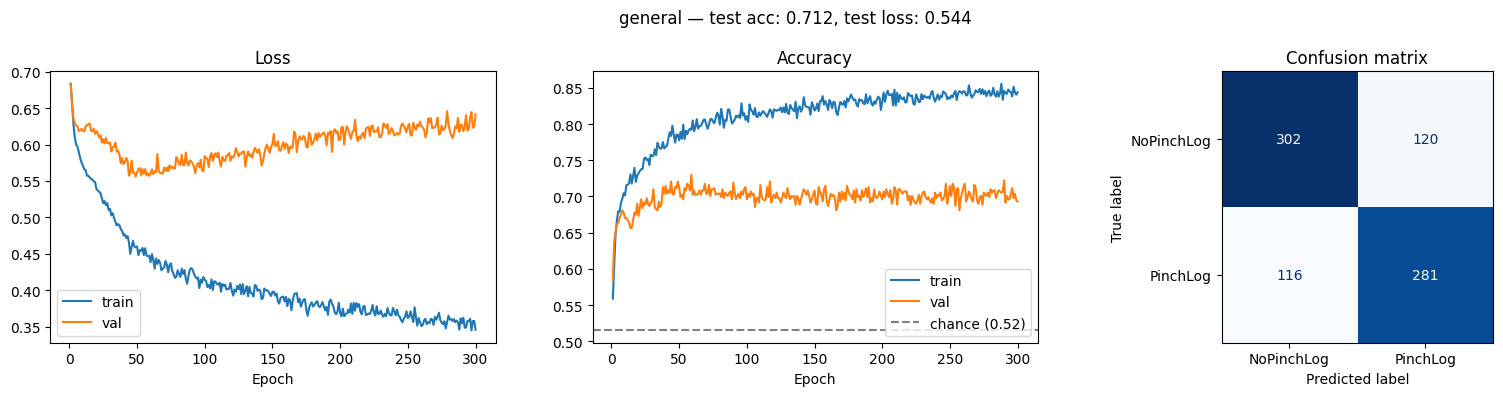

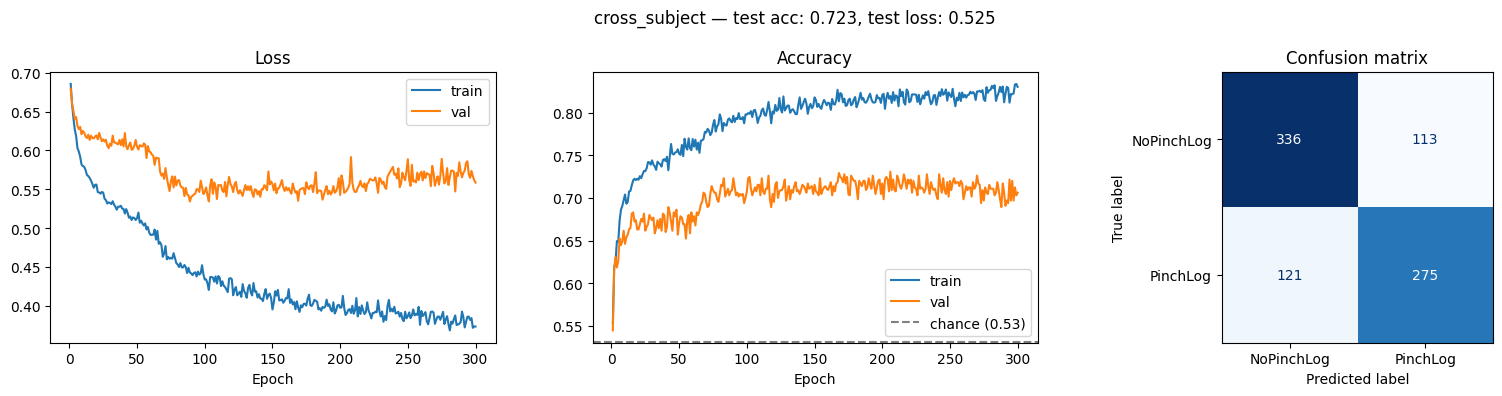

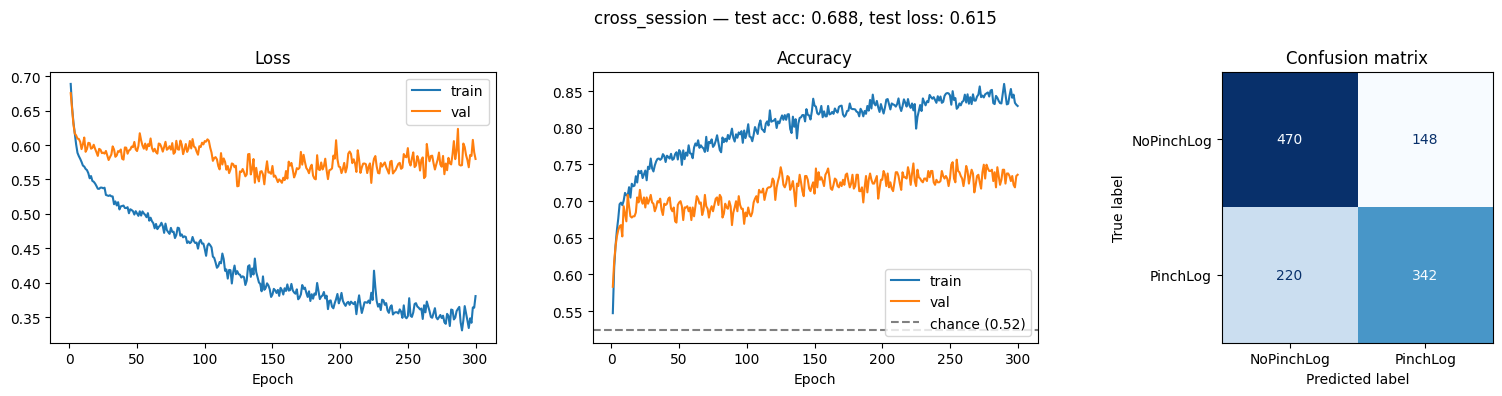

In [23]:
_ = plot_run(results_general, run_name="general")
_ = plot_run(results_cross_subject, run_name="cross_subject")
_ = plot_run(results_cross_session, run_name="cross_session")

### Comparing with hard-negatives

## Multi-Branch GAT-GRU-Transformer

Wang Z and Wang Y (2025)

Input:

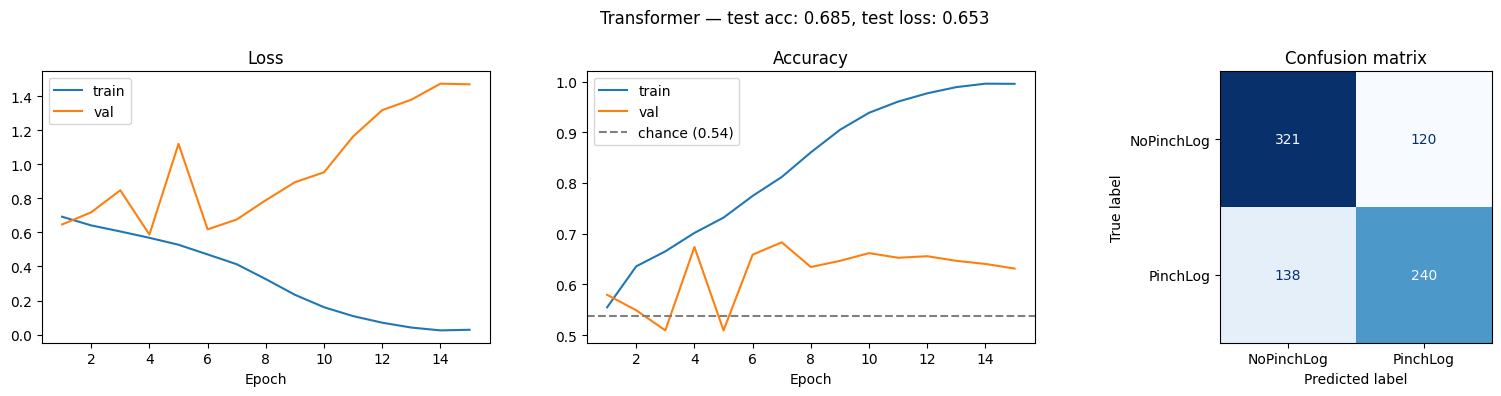

In [28]:
_ = plot_run(out, run_name="Transformer")